<a href="https://colab.research.google.com/github/Karnesh12/J26-IT-346/blob/hand-fracture-detection-and-classification/notebooks/Hand_fracture_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

DATA_ROOT = Path(
    "/content/drive/MyDrive/Hand fracture detection and classification/Hand Final"
)

print("Dataset exists:", DATA_ROOT.exists())
print("Dataset path:", DATA_ROOT)


Dataset exists: True
Dataset path: /content/drive/MyDrive/Hand fracture detection and classification/Hand Final


In [ ]:

from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for class_name in ["Fractured", "Non-Fractured"]:
    class_path = DATA_ROOT / class_name

    print(f"\n{'=' * 45}")
    print(f"CLASS: {class_name}")
    print(f"{'=' * 45}")

    if not class_path.exists():
        print("ERROR: Folder not found:", class_path)
        continue

    for folder in sorted(class_path.iterdir()):
        if folder.is_dir():
            images = [
                p for p in folder.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            ]

            print(f"{folder.name}: {len(images)} images")



CLASS: Fractured
Elbow to Wrist ( Radius, Ulna): 304 images
Shoulder point to Elbow (Humerus): 197 images
Wrist and Hand ( Carpals, Metacarpals, Phalanges): 122 images

CLASS: Non-Fractured
Elbow to Wrist ( Radius, Ulna): 51 images
Shoulder point to Elbow (Humerus): 25 images
Wrist and Hand ( Carpals, Metacarpals, Phalanges): 102 images


In [ ]:

from pathlib import Path

print("DATASET ROOT:")
print(DATA_ROOT)

for class_name in ["Fractured", "Non-Fractured"]:
    class_path = DATA_ROOT / class_name

    print(f"\n--- {class_name} ---")
    print("Folder exists:", class_path.exists())

    if class_path.exists():
        for folder in sorted(class_path.iterdir()):
            if folder.is_dir():
                print(repr(folder.name))


DATASET ROOT:
/content/drive/MyDrive/Hand fracture detection and classification/Hand Final

--- Fractured ---
Folder exists: True
'Elbow to Wrist ( Radius, Ulna)'
'Shoulder point to Elbow (Humerus)'
'Wrist and Hand ( Carpals, Metacarpals, Phalanges)'

--- Non-Fractured ---
Folder exists: True
'Elbow to Wrist ( Radius, Ulna)'
'Shoulder point to Elbow (Humerus)'
'Wrist and Hand ( Carpals, Metacarpals, Phalanges)'


In [ ]:

for class_name in ["Fractured", "Non-Fractured"]:
    class_path = DATA_ROOT / class_name

    print(f"\n{class_name}")

    for folder in sorted(class_path.iterdir()):
        if folder.is_dir():
            count = sum(
                1 for p in folder.rglob("*")
                if p.is_file()
                and p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".bmp"
                }
            )

            print(f"{folder.name}: {count} images")



Fractured
Elbow to Wrist ( Radius, Ulna): 304 images
Shoulder point to Elbow (Humerus): 197 images
Wrist and Hand ( Carpals, Metacarpals, Phalanges): 122 images

Non-Fractured
Elbow to Wrist ( Radius, Ulna): 51 images
Shoulder point to Elbow (Humerus): 25 images
Wrist and Hand ( Carpals, Metacarpals, Phalanges): 102 images


In [ ]:

import pandas as pd
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# Define the two fracture classes
FRACTURE_LABELS = {
    "Non-Fractured": 0,
    "Fractured": 1
}

# Read the exact anatomical folder names
fractured_root = DATA_ROOT / "Fractured"

REGION_LABELS = {
    folder.name: index
    for index, folder in enumerate(
        sorted(p for p in fractured_root.iterdir() if p.is_dir())
    )
}

records = []

for class_name, fracture_label in FRACTURE_LABELS.items():
    for region_name, region_label in REGION_LABELS.items():

        folder = DATA_ROOT / class_name / region_name

        if not folder.exists():
            raise FileNotFoundError(f"Missing folder: {folder}")

        for image_path in folder.rglob("*"):
            if (
                image_path.is_file()
                and image_path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                records.append({
                    "image_path": str(image_path),
                    "fracture_label": fracture_label,
                    "region_label": region_label,
                    "fracture_name": class_name,
                    "region_name": region_name
                })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("\nImages per class:")
print(df["fracture_name"].value_counts())

print("\nImages per anatomical region:")
print(df["region_name"].value_counts())

print("\nFracture status by region:")
print(pd.crosstab(df["fracture_name"], df["region_name"]))


Total images: 801

Images per class:
fracture_name
Fractured        623
Non-Fractured    178
Name: count, dtype: int64

Images per anatomical region:
region_name
Elbow to Wrist ( Radius, Ulna)                       355
Wrist and Hand ( Carpals, Metacarpals, Phalanges)    224
Shoulder point to Elbow (Humerus)                    222
Name: count, dtype: int64

Fracture status by region:
region_name    Elbow to Wrist ( Radius, Ulna)  \
fracture_name                                   
Fractured                                 304   
Non-Fractured                              51   

region_name    Shoulder point to Elbow (Humerus)  \
fracture_name                                      
Fractured                                    197   
Non-Fractured                                 25   

region_name    Wrist and Hand ( Carpals, Metacarpals, Phalanges)  
fracture_name                                                     
Fractured                                                    122  
Non-Fr

In [ ]:

summary = (
    df.groupby(["region_name", "fracture_name"])
      .size()
      .unstack(fill_value=0)
)

display(summary)


fracture_name,Fractured,Non-Fractured
region_name,,
"Elbow to Wrist ( Radius, Ulna)",304,51
Shoulder point to Elbow (Humerus),197,25
"Wrist and Hand ( Carpals, Metacarpals, Phalanges)",122,102


In [ ]:

import hashlib
from collections import defaultdict

hash_to_paths = defaultdict(list)

for image_path in df["image_path"]:
    sha256 = hashlib.sha256()

    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    hash_to_paths[sha256.hexdigest()].append(image_path)

duplicate_groups = {
    digest: paths
    for digest, paths in hash_to_paths.items()
    if len(paths) > 1
}

print("Total images:", len(df))
print("Unique image contents:", len(hash_to_paths))
print("Duplicate groups:", len(duplicate_groups))

for paths in list(duplicate_groups.values())[:5]:
    print("\nDuplicate files:")
    for path in paths:
        print(path)


Total images: 801
Unique image contents: 800
Duplicate groups: 1

Duplicate files:
/content/drive/MyDrive/Hand fracture detection and classification/Hand Final/Fractured/Elbow to Wrist ( Radius, Ulna)/fracture_forearm_0266.jpg
/content/drive/MyDrive/Hand fracture detection and classification/Hand Final/Fractured/Elbow to Wrist ( Radius, Ulna)/fracture_forearm_0024.jpg


In [ ]:

duplicate_paths = [
    path
    for paths in duplicate_groups.values()
    for path in paths
]

# Keep the first copy in each duplicate group and exclude the others
duplicate_paths_to_exclude = {
    path for paths in duplicate_groups.values()
    for path in paths[1:]
}

df_clean = df[
    ~df["image_path"].isin(duplicate_paths_to_exclude)
].copy()

print("Original indexed images:", len(df))
print("Images after excluding exact duplicates:", len(df_clean))
print("\nClass counts:")
print(df_clean["fracture_name"].value_counts())

print("\nRegion and fracture counts:")
display(
    df_clean.groupby(["region_name", "fracture_name"])
    .size()
    .unstack(fill_value=0)
)


Original indexed images: 801
Images after excluding exact duplicates: 800

Class counts:
fracture_name
Fractured        622
Non-Fractured    178
Name: count, dtype: int64

Region and fracture counts:


fracture_name,Fractured,Non-Fractured
region_name,,
"Elbow to Wrist ( Radius, Ulna)",303,51
Shoulder point to Elbow (Humerus),197,25
"Wrist and Hand ( Carpals, Metacarpals, Phalanges)",122,102


In [ ]:

from sklearn.model_selection import train_test_split

SEED = 42

# df_clean contains 800 images after exact duplicate exclusion.
# Stratify by the combined fracture status and region.
df_clean = df_clean.copy()

df_clean["stratify_label"] = (
    df_clean["fracture_name"].astype(str)
    + " | "
    + df_clean["region_name"].astype(str)
)

print("Images before splitting:", len(df_clean))
print("\nImages per combined class:")
print(df_clean["stratify_label"].value_counts())

# 70% training, 30% temporary set
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=SEED,
    stratify=df_clean["stratify_label"]
)

# Divide temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["stratify_label"]
)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining distribution:")
display(pd.crosstab(
    train_df["region_name"],
    train_df["fracture_name"]
))

print("\nValidation distribution:")
display(pd.crosstab(
    val_df["region_name"],
    val_df["fracture_name"]
))

print("\nTest distribution:")
display(pd.crosstab(
    test_df["region_name"],
    test_df["fracture_name"]
))


Images before splitting: 800

Images per combined class:
stratify_label
Fractured | Elbow to Wrist ( Radius, Ulna)                           303
Fractured | Shoulder point to Elbow (Humerus)                        197
Fractured | Wrist and Hand ( Carpals, Metacarpals, Phalanges)        122
Non-Fractured | Wrist and Hand ( Carpals, Metacarpals, Phalanges)    102
Non-Fractured | Elbow to Wrist ( Radius, Ulna)                        51
Non-Fractured | Shoulder point to Elbow (Humerus)                     25
Name: count, dtype: int64

Training images: 560
Validation images: 120
Test images: 120
Total: 800

Training distribution:


fracture_name,Fractured,Non-Fractured
region_name,,
"Elbow to Wrist ( Radius, Ulna)",212,36
Shoulder point to Elbow (Humerus),138,18
"Wrist and Hand ( Carpals, Metacarpals, Phalanges)",85,71



Validation distribution:


fracture_name,Fractured,Non-Fractured
region_name,,
"Elbow to Wrist ( Radius, Ulna)",45,7
Shoulder point to Elbow (Humerus),30,4
"Wrist and Hand ( Carpals, Metacarpals, Phalanges)",18,16



Test distribution:


fracture_name,Fractured,Non-Fractured
region_name,,
"Elbow to Wrist ( Radius, Ulna)",46,8
Shoulder point to Elbow (Humerus),29,3
"Wrist and Hand ( Carpals, Metacarpals, Phalanges)",19,15


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

import numpy as np
import pandas as pd
import copy
import time
from pathlib import Path

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


image transformation


In [ ]:

IMAGE_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations created.")


Image transformations created.


In [ ]:

class UpperLimbDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        fracture_label = torch.tensor(
            int(row["fracture_label"]), dtype=torch.long
        )

        region_label = torch.tensor(
            int(row["region_label"]), dtype=torch.long
        )

        return image, fracture_label, region_label


train_dataset = UpperLimbDataset(train_df, train_transform)
val_dataset = UpperLimbDataset(val_df, eval_transform)
test_dataset = UpperLimbDataset(test_df, eval_transform)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))


Training dataset: 560
Validation dataset: 120
Testing dataset: 120


In [ ]:

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

images, fracture_labels, region_labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Fracture labels shape:", fracture_labels.shape)
print("Region labels shape:", region_labels.shape)


Image batch shape: torch.Size([16, 3, 224, 224])
Fracture labels shape: torch.Size([16])
Region labels shape: torch.Size([16])


 # ResNet-50

In [ ]:

import torch
import torch.nn as nn
from torchvision import models

class MultiTaskResNet50(nn.Module):
    def __init__(self):
        super().__init__()

        # Load ImageNet-pretrained ResNet-50
        backbone = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        feature_count = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.backbone = backbone

        # Initially freeze the pretrained backbone
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

        # Two classification heads
        self.fracture_head = nn.Linear(feature_count, 2)
        self.region_head = nn.Linear(feature_count, 3)

    def forward(self, x):
        features = self.backbone(x)

        fracture_logits = self.fracture_head(features)
        region_logits = self.region_head(features)

        return fracture_logits, region_logits


resnet_model = MultiTaskResNet50().to(device)

print("ResNet-50 initialized successfully.")
print("Device:", device)
print("Fracture classes: 2")
print("Anatomical region classes: 3")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


ResNet-50 initialized successfully.
Device: cpu
Fracture classes: 2
Anatomical region classes: 3


In [ ]:

import copy
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# Training settings
NUM_EPOCHS = 8
LEARNING_RATE = 0.001

# Save results to Google Drive
SAVE_DIR = Path(
    "/content/drive/MyDrive/Hand fracture detection and classification/Model Results"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = SAVE_DIR / "resnet50_best.pth"

# Loss functions for both tasks
fracture_criterion = nn.CrossEntropyLoss()
region_criterion = nn.CrossEntropyLoss()

# Train the two output heads first
optimizer = optim.AdamW(
    list(resnet_model.fracture_head.parameters()) +
    list(resnet_model.region_head.parameters()),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

best_val_loss = float("inf")
best_state = None
history = []

print("Training configuration ready.")
print("Epochs:", NUM_EPOCHS)
print("Save path:", BEST_MODEL_PATH)


Training configuration ready.
Epochs: 8
Save path: /content/drive/MyDrive/Hand fracture detection and classification/Model Results/resnet50_best.pth


In [ ]:

for epoch in range(NUM_EPOCHS):

    # ---------------- TRAINING ----------------
    resnet_model.train()

    train_loss_sum = 0.0
    train_fracture_correct = 0
    train_region_correct = 0
    train_total = 0

    for images, fracture_y, region_y in train_loader:
        images = images.to(device)
        fracture_y = fracture_y.to(device)
        region_y = region_y.to(device)

        optimizer.zero_grad()

        fracture_logits, region_logits = resnet_model(images)

        fracture_loss = fracture_criterion(
            fracture_logits, fracture_y
        )
        region_loss = region_criterion(
            region_logits, region_y
        )

        loss = fracture_loss + region_loss
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        train_loss_sum += loss.item() * batch_size
        train_total += batch_size

        train_fracture_correct += (
            fracture_logits.argmax(1) == fracture_y
        ).sum().item()

        train_region_correct += (
            region_logits.argmax(1) == region_y
        ).sum().item()

    train_loss = train_loss_sum / train_total
    train_fracture_acc = train_fracture_correct / train_total
    train_region_acc = train_region_correct / train_total

    # ---------------- VALIDATION ----------------
    resnet_model.eval()

    val_loss_sum = 0.0
    val_fracture_correct = 0
    val_region_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, fracture_y, region_y in val_loader:
            images = images.to(device)
            fracture_y = fracture_y.to(device)
            region_y = region_y.to(device)

            fracture_logits, region_logits = resnet_model(images)

            fracture_loss = fracture_criterion(
                fracture_logits, fracture_y
            )
            region_loss = region_criterion(
                region_logits, region_y
            )

            loss = fracture_loss + region_loss

            batch_size = images.size(0)
            val_loss_sum += loss.item() * batch_size
            val_total += batch_size

            val_fracture_correct += (
                fracture_logits.argmax(1) == fracture_y
            ).sum().item()

            val_region_correct += (
                region_logits.argmax(1) == region_y
            ).sum().item()

    val_loss = val_loss_sum / val_total
    val_fracture_acc = val_fracture_correct / val_total
    val_region_acc = val_region_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_fracture_accuracy": train_fracture_acc,
        "val_fracture_accuracy": val_fracture_acc,
        "train_region_accuracy": train_region_acc,
        "val_region_accuracy": val_region_acc
    })

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Fracture Val Acc: {val_fracture_acc:.3f} | "
        f"Region Val Acc: {val_region_acc:.3f}"
    )

    # Save the best checkpoint using validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(resnet_model.state_dict())

        torch.save({
            "architecture": "ResNet-50",
            "model_state_dict": best_state,
            "fracture_classes": ["Non-Fractured", "Fractured"],
            "region_classes": {
                name: label for name, label in REGION_LABELS.items()
            },
            "image_size": IMAGE_SIZE
        }, BEST_MODEL_PATH)

print("\nResNet-50 training completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Saved checkpoint:", BEST_MODEL_PATH)


Epoch 1/8 | Train Loss: 1.3731 | Val Loss: 1.2158 | Fracture Val Acc: 0.800 | Region Val Acc: 0.792
Epoch 2/8 | Train Loss: 1.0268 | Val Loss: 0.9110 | Fracture Val Acc: 0.875 | Region Val Acc: 0.833
Epoch 3/8 | Train Loss: 0.9035 | Val Loss: 0.8263 | Fracture Val Acc: 0.892 | Region Val Acc: 0.808
Epoch 4/8 | Train Loss: 0.8519 | Val Loss: 0.7627 | Fracture Val Acc: 0.892 | Region Val Acc: 0.825
Epoch 5/8 | Train Loss: 0.7627 | Val Loss: 0.7471 | Fracture Val Acc: 0.900 | Region Val Acc: 0.825
Epoch 6/8 | Train Loss: 0.7387 | Val Loss: 0.7179 | Fracture Val Acc: 0.892 | Region Val Acc: 0.850
Epoch 7/8 | Train Loss: 0.7082 | Val Loss: 0.6809 | Fracture Val Acc: 0.917 | Region Val Acc: 0.850
Epoch 8/8 | Train Loss: 0.6700 | Val Loss: 0.6744 | Fracture Val Acc: 0.933 | Region Val Acc: 0.858

ResNet-50 training completed.
Best validation loss: 0.6744
Saved checkpoint: /content/drive/MyDrive/Hand fracture detection and classification/Model Results/resnet50_best.pth


In [ ]:

import pandas as pd
from IPython.display import display, Markdown

# Create the ResNet-50 training history table
resnet_results = pd.DataFrame(history)

print("=" * 55)
print("RESNET-50 MODEL — VALIDATION SUMMARY")
print("=" * 55)

print(f"Architecture: ResNet-50")
print(f"Training images: {len(train_df)}")
print(f"Validation images: {len(val_df)}")
print(f"Test images reserved: {len(test_df)}")
print(f"Epochs completed: {len(history)}")
print(f"Best validation loss: {best_val_loss:.4f}")

best_epoch_row = resnet_results.loc[
    resnet_results["val_loss"].idxmin()
]

print(f"Best epoch: {int(best_epoch_row['epoch'])}")
print(
    "Fracture validation accuracy: "
    f"{best_epoch_row['val_fracture_accuracy'] * 100:.2f}%"
)
print(
    "Region validation accuracy: "
    f"{best_epoch_row['val_region_accuracy'] * 100:.2f}%"
)

print("\nComplete training history:")
display(resnet_results.round(4))

# Save the results to Google Drive
resnet_results.to_csv(
    SAVE_DIR / "resnet50_training_history.csv",
    index=False
)

print("\nResults saved to:", SAVE_DIR / "resnet50_training_history.csv")


RESNET-50 MODEL — VALIDATION SUMMARY
Architecture: ResNet-50
Training images: 560
Validation images: 120
Test images reserved: 120
Epochs completed: 0
Best validation loss: inf


KeyError: 'val_loss'

In [ ]:
import matplotlib.pyplot as plt

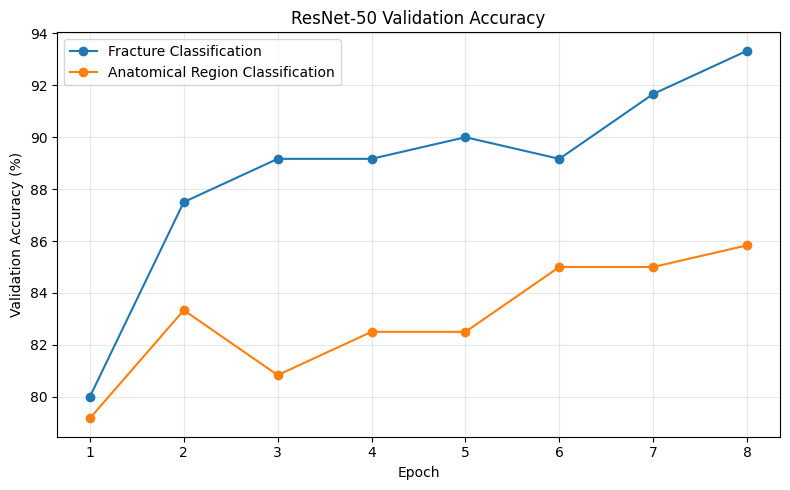

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    resnet_results["epoch"],
    resnet_results["val_fracture_accuracy"] * 100,
    marker="o",
    label="Fracture Classification"
)

plt.plot(
    resnet_results["epoch"],
    resnet_results["val_region_accuracy"] * 100,
    marker="o",
    label="Anatomical Region Classification"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("ResNet-50 Validation Accuracy")
plt.xticks(resnet_results["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    SAVE_DIR / "resnet50_validation_accuracy.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


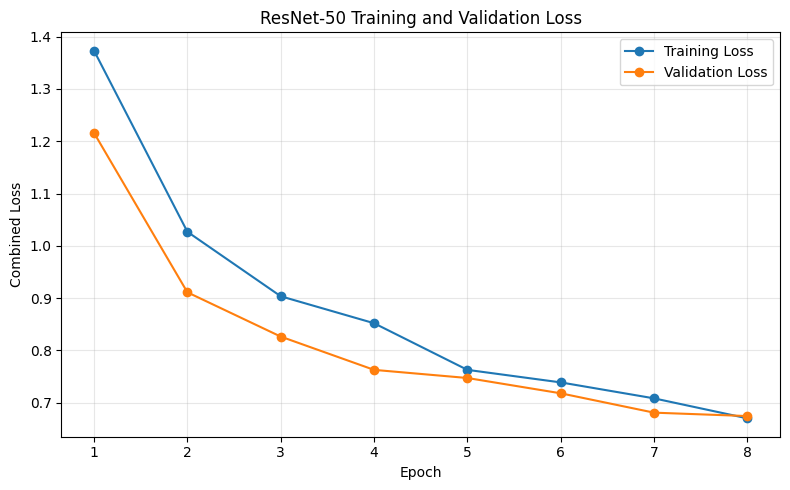

In [ ]:



plt.figure(figsize=(8, 5))

plt.plot(
    resnet_results["epoch"],
    resnet_results["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    resnet_results["epoch"],
    resnet_results["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Loss")
plt.title("ResNet-50 Training and Validation Loss")
plt.xticks(resnet_results["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    SAVE_DIR / "resnet50_loss_curve.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


### Experiment 1: ResNet-50 Transfer Learning

**Objective:** Develop a multi-task image-classification model to predict fracture presence and anatomical region from upper-limb X-rays.

**Dataset:** 800 images after excluding one exact duplicate. The images were divided into 560 training, 120 validation and 120 test images.

**Architecture:** ImageNet-pretrained ResNet-50 with two classification heads:
- Fracture presence: Fractured / Non-Fractured.
- Anatomical region: Forearm / Upper arm / Wrist and Hand.

**Training configuration:** Eight epochs, frozen pretrained backbone, AdamW optimizer and a learning rate of 0.001.

**Preliminary validation results:**
- Best combined validation loss: 0.6624.
- Fracture validation accuracy: 91.67%.
- Anatomical-region validation accuracy: 85.83%.

**Limitation:** These are preliminary validation results. Final performance must be evaluated on the held-out test set. Patient-level independence has not been established because patient IDs are unavailable.

**Next experiment:** Train DenseNet-121 under comparable conditions and compare both models using fracture-specific and region-specific evaluation metrics.

# DenseNet-121

In [ ]:

import torch
import torch.nn as nn
from torchvision import models

class MultiTaskDenseNet121(nn.Module):
    def __init__(self):
        super().__init__()

        backbone = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )

        feature_count = backbone.classifier.in_features
        backbone.classifier = nn.Identity()

        self.backbone = backbone

        # Freeze the pretrained feature extractor
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

        # Output 1: fracture status (2 classes)
        self.fracture_head = nn.Linear(feature_count, 2)

        # Output 2: anatomical region (3 classes)
        self.region_head = nn.Linear(feature_count, 3)

    def forward(self, x):
        features = self.backbone(x)

        fracture_logits = self.fracture_head(features)
        region_logits = self.region_head(features)

        return fracture_logits, region_logits


densenet_model = MultiTaskDenseNet121().to(device)

print("DenseNet-121 initialized successfully.")
print("Device:", device)
print("Fracture classes:", 2)
print("Anatomical region classes:", 3)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 170MB/s] 


DenseNet-121 initialized successfully.
Device: cpu
Fracture classes: 2
Anatomical region classes: 3


In [ ]:

NUM_EPOCHS = 8
LEARNING_RATE = 0.001

DENSENET_PATH = SAVE_DIR / "densenet121_best.pth"

fracture_criterion = nn.CrossEntropyLoss()
region_criterion = nn.CrossEntropyLoss()

optimizer_dense = torch.optim.AdamW(
    list(densenet_model.fracture_head.parameters()) +
    list(densenet_model.region_head.parameters()),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

best_dense_val_loss = float("inf")
best_dense_state = None
dense_history = []

print("DenseNet-121 training configuration ready.")
print("Epochs:", NUM_EPOCHS)
print("Checkpoint path:", DENSENET_PATH)


DenseNet-121 training configuration ready.
Epochs: 8
Checkpoint path: /content/drive/MyDrive/Hand fracture detection and classification/Model Results/densenet121_best.pth


In [ ]:

for epoch in range(NUM_EPOCHS):

    # Training phase
    densenet_model.train()

    train_loss_sum = 0.0
    train_total = 0

    for images, fracture_y, region_y in train_loader:
        images = images.to(device)
        fracture_y = fracture_y.to(device)
        region_y = region_y.to(device)

        optimizer_dense.zero_grad()

        fracture_logits, region_logits = densenet_model(images)

        loss_fracture = fracture_criterion(
            fracture_logits, fracture_y
        )
        loss_region = region_criterion(
            region_logits, region_y
        )

        loss = loss_fracture + loss_region
        loss.backward()
        optimizer_dense.step()

        train_loss_sum += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss = train_loss_sum / train_total

    # Validation phase
    densenet_model.eval()

    val_loss_sum = 0.0
    val_total = 0
    fracture_correct = 0
    region_correct = 0

    with torch.no_grad():
        for images, fracture_y, region_y in val_loader:
            images = images.to(device)
            fracture_y = fracture_y.to(device)
            region_y = region_y.to(device)

            fracture_logits, region_logits = densenet_model(images)

            loss = (
                fracture_criterion(fracture_logits, fracture_y)
                + region_criterion(region_logits, region_y)
            )

            val_loss_sum += loss.item() * images.size(0)
            val_total += images.size(0)

            fracture_correct += (
                fracture_logits.argmax(dim=1) == fracture_y
            ).sum().item()

            region_correct += (
                region_logits.argmax(dim=1) == region_y
            ).sum().item()

    val_loss = val_loss_sum / val_total
    fracture_acc = fracture_correct / val_total
    region_acc = region_correct / val_total

    dense_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_fracture_accuracy": fracture_acc,
        "val_region_accuracy": region_acc
    })

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Fracture Acc: {fracture_acc:.3f} | "
        f"Region Acc: {region_acc:.3f}"
    )

    # Save best validation checkpoint
    if val_loss < best_dense_val_loss:
        best_dense_val_loss = val_loss
        best_dense_state = {
            key: value.detach().cpu().clone()
            for key, value in densenet_model.state_dict().items()
        }

        torch.save({
            "architecture": "DenseNet-121",
            "model_state_dict": best_dense_state,
            "fracture_classes": ["Non-Fractured", "Fractured"],
            "region_classes": {
                name: label for name, label in REGION_LABELS.items()
            },
            "image_size": IMAGE_SIZE
        }, DENSENET_PATH)

print("\nDenseNet-121 training completed.")
print("Best validation loss:", round(best_dense_val_loss, 4))
print("Saved checkpoint:", DENSENET_PATH)


Epoch 1/8 | Train Loss: 1.3888 | Val Loss: 1.1045 | Fracture Acc: 0.908 | Region Acc: 0.683
Epoch 2/8 | Train Loss: 1.0292 | Val Loss: 0.8853 | Fracture Acc: 0.900 | Region Acc: 0.742
Epoch 3/8 | Train Loss: 0.8742 | Val Loss: 0.7766 | Fracture Acc: 0.883 | Region Acc: 0.875
Epoch 4/8 | Train Loss: 0.7928 | Val Loss: 0.7376 | Fracture Acc: 0.892 | Region Acc: 0.883
Epoch 5/8 | Train Loss: 0.7424 | Val Loss: 0.6978 | Fracture Acc: 0.908 | Region Acc: 0.858
Epoch 6/8 | Train Loss: 0.7515 | Val Loss: 0.7157 | Fracture Acc: 0.875 | Region Acc: 0.867
Epoch 7/8 | Train Loss: 0.7035 | Val Loss: 0.6749 | Fracture Acc: 0.892 | Region Acc: 0.867
Epoch 8/8 | Train Loss: 0.6716 | Val Loss: 0.6823 | Fracture Acc: 0.892 | Region Acc: 0.867

DenseNet-121 training completed.
Best validation loss: 0.6749
Saved checkpoint: /content/drive/MyDrive/Hand fracture detection and classification/Model Results/densenet121_best.pth


In [ ]:

dense_results = pd.DataFrame(dense_history)

display(dense_results.round(4))

dense_results.to_csv(
    SAVE_DIR / "densenet121_training_history.csv",
    index=False
)

print(
    "Training history saved to:",
    SAVE_DIR / "densenet121_training_history.csv"
)


,epoch,train_loss,val_loss,val_fracture_accuracy,val_region_accuracy
0,1,1.3888,1.1045,0.9083,0.6833
1,2,1.0292,0.8853,0.9000,0.7417
2,3,0.8742,0.7766,0.8833,0.8750
3,4,0.7928,0.7376,0.8917,0.8833
4,5,0.7424,0.6978,0.9083,0.8583
5,6,0.7515,0.7157,0.8750,0.8667
6,7,0.7035,0.6749,0.8917,0.8667
7,8,0.6716,0.6823,0.8917,0.8667


Training history saved to: /content/drive/MyDrive/Hand fracture detection and classification/Model Results/densenet121_training_history.csv


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import torch
import pandas as pd

def evaluate_checkpoint(model, checkpoint_path, loader, device):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    true_fracture, pred_fracture = [], []
    true_region, pred_region = [], []

    with torch.no_grad():
        for images, fracture_y, region_y in loader:
            images = images.to(device)

            fracture_logits, region_logits = model(images)

            true_fracture.extend(fracture_y.numpy().tolist())
            true_region.extend(region_y.numpy().tolist())

            pred_fracture.extend(
                fracture_logits.argmax(1).cpu().numpy().tolist()
            )
            pred_region.extend(
                region_logits.argmax(1).cpu().numpy().tolist()
            )

    def metrics(y_true, y_pred):
        return {
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(
                y_true, y_pred
            ),
            "Macro precision": precision_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "Macro recall": recall_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "Macro F1": f1_score(
                y_true, y_pred, average="macro", zero_division=0
            )
        }

    return {
        "Fracture": metrics(true_fracture, pred_fracture),
        "Region": metrics(true_region, pred_region)
    }


# Evaluate saved best checkpoints on validation data only
resnet_val = evaluate_checkpoint(
    resnet_model,
    SAVE_DIR / "resnet50_best.pth",
    val_loader,
    device
)

dense_val = evaluate_checkpoint(
    densenet_model,
    SAVE_DIR / "densenet121_best.pth",
    val_loader,
    device
)

rows = []

for model_name, results in [
    ("ResNet-50", resnet_val),
    ("DenseNet-121", dense_val)
]:
    for task, scores in results.items():
        rows.append({
            "Model": model_name,
            "Task": task,
            **scores
        })

comparison_df = pd.DataFrame(rows)

display(
    comparison_df.style.format({
        "Accuracy": "{:.3f}",
        "Balanced accuracy": "{:.3f}",
        "Macro precision": "{:.3f}",
        "Macro recall": "{:.3f}",
        "Macro F1": "{:.3f}"
    })
)

comparison_df.to_csv(
    SAVE_DIR / "validation_model_comparison.csv",
    index=False
)

print("Validation comparison saved to Google Drive.")


,Model,Task,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1
0,ResNet-50,Fracture,0.933,0.904,0.904,0.904,0.904
1,ResNet-50,Region,0.858,0.871,0.862,0.871,0.864
2,DenseNet-121,Fracture,0.892,0.878,0.837,0.878,0.854
3,DenseNet-121,Region,0.867,0.853,0.889,0.853,0.866


Validation comparison saved to Google Drive.


In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

def get_test_predictions(model, checkpoint_path, loader, device):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    y_fracture, p_fracture = [], []
    y_region, p_region = [], []

    with torch.no_grad():
        for images, fracture_y, region_y in loader:
            images = images.to(device)

            fracture_logits, region_logits = model(images)

            y_fracture.extend(fracture_y.numpy())
            y_region.extend(region_y.numpy())

            p_fracture.extend(
                fracture_logits.argmax(1).cpu().numpy()
            )
            p_region.extend(
                region_logits.argmax(1).cpu().numpy()
            )

    return (
        np.array(y_fracture),
        np.array(p_fracture),
        np.array(y_region),
        np.array(p_region)
    )


test_models = {
    "ResNet-50": (
        resnet_model,
        SAVE_DIR / "resnet50_best.pth"
    ),
    "DenseNet-121": (
        densenet_model,
        SAVE_DIR / "densenet121_best.pth"
    )
}

fracture_names = ["Non-Fractured", "Fractured"]

region_names = [
    name for name, label in sorted(
        REGION_LABELS.items(), key=lambda item: item[1]
    )
]

test_results = {}

for model_name, (model, checkpoint_path) in test_models.items():
    predictions = get_test_predictions(
        model, checkpoint_path, test_loader, device
    )

    y_f, p_f, y_r, p_r = predictions

    test_results[model_name] = predictions

    print("\n" + "=" * 60)
    print(model_name, "— FRACTURE TEST RESULTS")
    print("=" * 60)

    print(classification_report(
        y_f, p_f,
        labels=[0, 1],
        target_names=fracture_names,
        zero_division=0,
        digits=3
    ))

    print("Fracture confusion matrix:")
    print(confusion_matrix(y_f, p_f, labels=[0, 1]))

    print("\n" + model_name, "— REGION TEST RESULTS")
    print(classification_report(
        y_r, p_r,
        labels=[0, 1, 2],
        target_names=region_names,
        zero_division=0,
        digits=3
    ))

    print("Region confusion matrix:")
    print(confusion_matrix(y_r, p_r, labels=[0, 1, 2]))



ResNet-50 — FRACTURE TEST RESULTS
               precision    recall  f1-score   support

Non-Fractured      0.875     0.808     0.840        26
    Fractured      0.948     0.968     0.958        94

     accuracy                          0.933       120
    macro avg      0.911     0.888     0.899       120
 weighted avg      0.932     0.933     0.932       120

Fracture confusion matrix:
[[21  5]
 [ 3 91]]

ResNet-50 — REGION TEST RESULTS
                                                   precision    recall  f1-score   support

                   Elbow to Wrist ( Radius, Ulna)      0.857     0.778     0.816        54
                Shoulder point to Elbow (Humerus)      0.756     0.969     0.849        32
Wrist and Hand ( Carpals, Metacarpals, Phalanges)      0.900     0.794     0.844        34

                                         accuracy                          0.833       120
                                        macro avg      0.838     0.847     0.836       120
     

# Implement Grad-CAM

In [ ]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Load the best saved ResNet-50 checkpoint
checkpoint = torch.load(
    SAVE_DIR / "resnet50_best.pth",
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model = resnet_model.to(device)
resnet_model.eval()

print("ResNet-50 checkpoint loaded successfully.")
print("Device:", device)


ResNet-50 checkpoint loaded successfully.
Device: cpu


In [ ]:

def generate_gradcam(model, image_tensor, target_class=None):
    model.eval()

    activations = {}
    gradients = {}

    target_layer = model.backbone.layer3

    def forward_hook(module, inputs, output):
        activations["value"] = output

    def backward_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )
    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    try:
        # Grad-CAM requires gradients, even during inference
        model.zero_grad(set_to_none=True)

        x = image_tensor.unsqueeze(0).to(device)
        x.requires_grad_(True)

        with torch.enable_grad():
            fracture_logits, region_logits = model(x)

            # Explain the predicted fracture class by default
            if target_class is None:
                target_class = int(fracture_logits.argmax(dim=1).item())

            score = fracture_logits[0, target_class]
            score.backward()

        feature_maps = activations["value"][0]
        grads = gradients["value"][0]

        # Average gradients over spatial dimensions
        weights = grads.mean(dim=(1, 2))

        # Weighted sum of feature maps
        cam = (weights[:, None, None] * feature_maps).sum(dim=0)
        cam = F.relu(cam)

        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        cam = F.interpolate(
            cam[None, None],
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        return (
            cam.detach().cpu().numpy(),
            fracture_logits.detach().cpu(),
            region_logits.detach().cpu(),
            target_class
        )

    finally:
        forward_handle.remove()
        backward_handle.remove()


True fracture label: 1
Predicted fracture: Fractured
Fracture softmax score: 0.897
Predicted region: Shoulder point to Elbow (Humerus)
Region softmax score: 0.534
Explained fracture class: Fractured


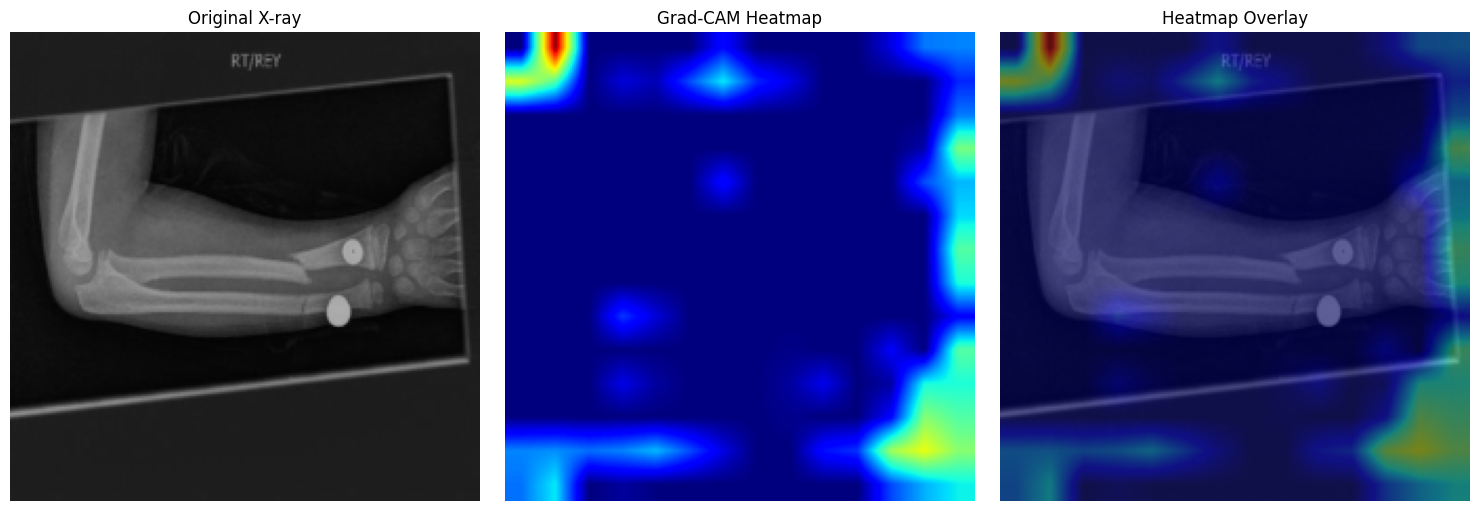

In [ ]:

# Select a test image
sample_index = 16
image_tensor, true_fracture, true_region = test_dataset[sample_index]

cam, fracture_logits, region_logits, explained_class = (
    generate_gradcam(resnet_model, image_tensor)
)

# Undo ImageNet normalization for visualization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = (image_tensor.cpu() * std + mean).clamp(0, 1)
display_image = display_image.permute(1, 2, 0).numpy()

# Convert the heatmap to a colored image
heatmap_color = plt.get_cmap("jet")(cam)[..., :3]

# Overlay the heatmap on the original image
overlay = 0.55 * display_image + 0.45 * heatmap_color
overlay = np.clip(overlay, 0, 1)

fracture_probs = torch.softmax(fracture_logits, dim=1)[0]
region_probs = torch.softmax(region_logits, dim=1)[0]

fracture_names = ["Non-Fractured", "Fractured"]
region_names = [
    name for name, label in sorted(
        REGION_LABELS.items(), key=lambda item: item[1]
    )
]

pred_fracture = int(fracture_probs.argmax())
pred_region = int(region_probs.argmax())

print("True fracture label:", int(true_fracture))
print("Predicted fracture:", fracture_names[pred_fracture])
print(f"Fracture softmax score: {fracture_probs[pred_fracture].item():.3f}")
print("Predicted region:", region_names[pred_region])
print(f"Region softmax score: {region_probs[pred_region].item():.3f}")
print("Explained fracture class:", fracture_names[explained_class])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(display_image, cmap="gray")
axes[0].set_title("Original X-ray")

axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title("Heatmap Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Verify the selected test image and its labels
sample_index = 16  # Use the index of the image you just inspected

image_tensor, true_fracture, true_region = test_dataset[sample_index]

print("Dataset index:", sample_index)
print("True fracture label:", int(true_fracture))
print("True region label:", int(true_region))

# Check the image path from your test dataframe
print("Image path:", test_df.iloc[sample_index]["image_path"])

# Recalculate the predictions for this exact tensor
cam, fracture_logits, region_logits, explained_class = (
    generate_gradcam(resnet_model, image_tensor)
)

fracture_probs = torch.softmax(fracture_logits, dim=1)[0]
region_probs = torch.softmax(region_logits, dim=1)[0]

print(
    "Predicted fracture:",
    ["Non-Fractured", "Fractured"][int(fracture_probs.argmax())]
)
print("Fracture scores:", fracture_probs.tolist())
print("Region scores:", region_probs.tolist())


Dataset index: 16
True fracture label: 1
True region label: 0
Image path: /content/drive/MyDrive/Hand fracture detection and classification/Hand Final/Fractured/Elbow to Wrist ( Radius, Ulna)/fracture_forearm_0046.jpg
Predicted fracture: Fractured
Fracture scores: [0.10251781344413757, 0.89748215675354]
Region scores: [0.2659921944141388, 0.5340814590454102, 0.19992639124393463]


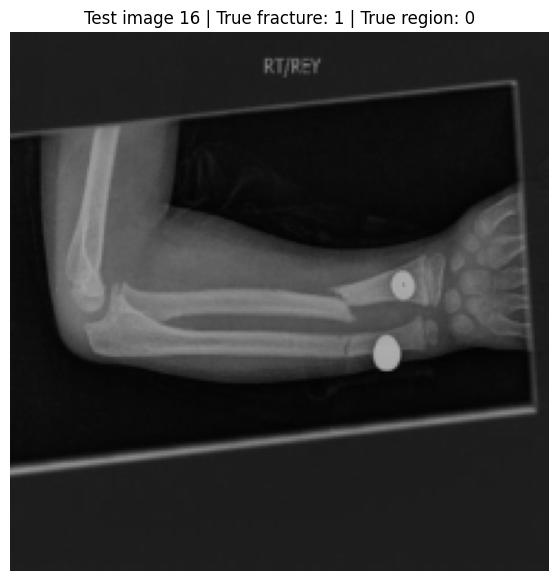

Image path: /content/drive/MyDrive/Hand fracture detection and classification/Hand Final/Fractured/Elbow to Wrist ( Radius, Ulna)/fracture_forearm_0046.jpg


In [ ]:

import matplotlib.pyplot as plt

sample_index = 16
image_tensor, true_fracture, true_region = test_dataset[sample_index]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

original = (image_tensor.cpu() * std + mean).clamp(0, 1)
original = original.permute(1, 2, 0).numpy()

plt.figure(figsize=(7, 7))
plt.imshow(original)
plt.title(
    f"Test image {sample_index} | "
    f"True fracture: {int(true_fracture)} | "
    f"True region: {int(true_region)}"
)
plt.axis("off")
plt.show()

print("Image path:", test_df.iloc[sample_index]["image_path"])


In [ ]:

print("Region label mapping:")

for region_name, region_id in sorted(
    REGION_LABELS.items(),
    key=lambda item: item[1]
):
    print(f"ID {region_id}: {region_name}")

print("\nExpected mapping:")
print("0 = Elbow to Wrist (Radius, Ulna)")
print("1 = Shoulder point to Elbow (Humerus)")
print("2 = Wrist and Hand (Carpals, Metacarpals, Phalanges)")


Region label mapping:
ID 0: Elbow to Wrist ( Radius, Ulna)
ID 1: Shoulder point to Elbow (Humerus)
ID 2: Wrist and Hand ( Carpals, Metacarpals, Phalanges)

Expected mapping:
0 = Elbow to Wrist (Radius, Ulna)
1 = Shoulder point to Elbow (Humerus)
2 = Wrist and Hand (Carpals, Metacarpals, Phalanges)


In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# Reuse the predictions from your previous test evaluation
y_region_true = test_results["ResNet-50"][2]
y_region_pred = test_results["ResNet-50"][3]

region_names = [
    name for name, label in sorted(
        REGION_LABELS.items(),
        key=lambda item: item[1]
    )
]

cm = confusion_matrix(
    y_region_true,
    y_region_pred,
    labels=[0, 1, 2]
)

display_labels = [
    "Elbow to Wrist",
    "Shoulder to Elbow",
    "Wrist and Hand"
]

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("ResNet-50 Anatomical Region — Test Confusion Matrix")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


NameError: name 'test_results' is not defined